Student Performance Prescriptive Analytics <10-31-26> - <maxram3385>

In [6]:
### Step 1: Load the Dataset

import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_excel(r"C:\Files\Excel\Project\StudentsPerformance.xlsx")
display(df.head())


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [7]:
### Step 2: Convert Categorical Columns Using One-Hot Encoding

categorical_columns = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course"
]

# Keep one category as the reference for each categorical variable.
encoded_df = pd.get_dummies(
    df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

display(encoded_df.head())


,math score,reading score,writing score,gender_male,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,lunch_standard,test preparation course_none
0,72,72,74,0,1,0,0,0,1,0,0,0,0,1,1
1,69,90,88,0,0,1,0,0,0,0,0,1,0,1,0
2,90,95,93,0,1,0,0,0,0,0,1,0,0,1,1
3,47,57,44,1,0,0,0,0,0,0,0,0,0,0,1
4,76,78,75,1,0,1,0,0,0,0,0,1,0,1,1


In [8]:

### Step 3: Split the Dataset into Training and Testing Sets

X = encoded_df.drop(columns=["math score"])
y = encoded_df["math score"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 800
Testing records: 200


In [9]:
### Step 4: Create and Train the Linear Regression Model

model = LinearRegression()
model.fit(X_train, y_train)

print("Linear regression model trained.")


### Step 5: Predict Math Scores and Evaluate the Model

y_pred = model.predict(X_test)

predictions = pd.DataFrame({
    "Actual Math Score": y_test,
    "Predicted Math Score": y_pred
})

display(predictions.head(10).round(2))

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r_squared = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared: {r_squared:.4f}")


Linear regression model trained.


,Actual Math Score,Predicted Math Score
521,91,76.39
737,53,58.89
740,80,76.99
660,74,76.85
411,84,87.63
678,81,79.01
626,69,64.65
513,54,53.01
859,87,74.18
136,51,49.21


Mean Absolute Error (MAE): 4.2148
Mean Squared Error (MSE): 29.0952
R-squared: 0.8804


In [10]:
### Step 5: Predict Math Scores and Evaluate the Model

y_pred = model.predict(X_test)

predictions = pd.DataFrame({
    "Actual Math Score": y_test,
    "Predicted Math Score": y_pred
})

display(predictions.head(10).round(2))

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r_squared = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared: {r_squared:.4f}")

,Actual Math Score,Predicted Math Score
521,91,76.39
737,53,58.89
740,80,76.99
660,74,76.85
411,84,87.63
678,81,79.01
626,69,64.65
513,54,53.01
859,87,74.18
136,51,49.21


Mean Absolute Error (MAE): 4.2148
Mean Squared Error (MSE): 29.0952
R-squared: 0.8804


In [11]:
### Step 6: Examine the Model Coefficients

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients["Absolute Coefficient"] = coefficients["Coefficient"].abs()

coefficients = coefficients.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

display(coefficients.round(4))

# Coefficients describe changes while other features are held constant.
# Numeric coefficients are per score point.
# Categorical coefficients are relative to the omitted reference category.
# Raw coefficient size does not establish statistical significance.

reading_coefficient = coefficients.loc[
    coefficients["Feature"] == "reading score",
    "Coefficient"
].iloc[0]

print(
    f"Each additional reading-score point changes predicted math score "
    f"by {reading_coefficient:.4f} points, holding other features constant."
)

categorical_coefficients = coefficients[
    ~coefficients["Feature"].isin(["reading score", "writing score"])
]

print("\nCategorical feature with the largest absolute coefficient:")
display(categorical_coefficients.head(1).round(4))


,Feature,Coefficient,Absolute Coefficient
2,gender_male,13.0649,13.0649
6,race/ethnicity_group E,4.8926,4.8926
12,lunch_standard,3.5101,3.5101
13,test preparation course_none,3.2896,3.2896
9,parental level of education_master's degree,-1.4005,1.4005
10,parental level of education_some college,0.9989,0.9989
8,parental level of education_high school,0.9293,0.9293
11,parental level of education_some high school,0.7565,0.7565
1,writing score,0.7241,0.7241
7,parental level of education_bachelor's degree,-0.7169,0.7169


Each additional reading-score point changes predicted math score by 0.2360 points, holding other features constant.

Categorical feature with the largest absolute coefficient:


,Feature,Coefficient,Absolute Coefficient
2,gender_male,13.0649,13.0649


### Step 7 — Actionable features | Assignment 5.5 | 11-07-26
Reading scores can change through instruction. A school could pilot small-group reading support using math word problems and track whether students improve in both subjects. Lunch status can reflect household resources. The scenario treats a change from free/reduced to standard lunch as a proxy for a change in circumstances. Schools can support students through meal access and family resource referrals. Changing a student's lunch code alone does not establish an effect on achievement.

In [12]:
### Step 8 — Simulate interventions for students below the median | Assignment 5.5 | 11-07-26
math_median = y.median()
before = X_test.loc[y_test < math_median].copy()
reading_only = before.copy()
reading_only["reading score"] = (before["reading score"] * 1.05).clip(upper=100)
after = reading_only.copy()

# Round half up because a lunch category can only change for a whole student.
eligible = before.loc[before["lunch_standard"] == 0]
n_changed = int(len(eligible) * 0.05 + 0.5)
changed_ids = eligible.sample(n=n_changed, random_state=42).index
after.loc[changed_ids, "lunch_standard"] = 1

results = pd.DataFrame({
    "Before": model.predict(before),
    "Reading only": model.predict(reading_only),
    "After": model.predict(after),
    "Lunch changed": before.index.isin(changed_ids)
}, index=before.index)
results["Gain"] = results["After"] - results["Before"]

print(f"Full dataset math median: {math_median:g} | Test students below median: {len(before)}")
print(f"Free/reduced lunch: {len(eligible)} before, {len(eligible) - n_changed} after")
print(f"Simulated change: {n_changed} students ({n_changed / len(eligible):.1%} of eligible students)")
print("Mean predicted math scores and gain (points):")
print(results[["Before", "Reading only", "After", "Gain"]].mean().round(2).to_string())
print("Mean gain by lunch scenario (points):")
print(results.groupby("Lunch changed")["Gain"].agg(["size", "mean"]).round(2).to_string())

Full dataset math median: 66 | Test students below median: 99
Free/reduced lunch: 50 before, 47 after
Simulated change: 3 students (6.0% of eligible students)
Mean predicted math scores and gain (points):
Before          53.76
Reading only    54.44
After           54.54
Gain             0.79
Mean gain by lunch scenario (points):
               size  mean
Lunch changed            
False            96  0.68
True              3  4.22


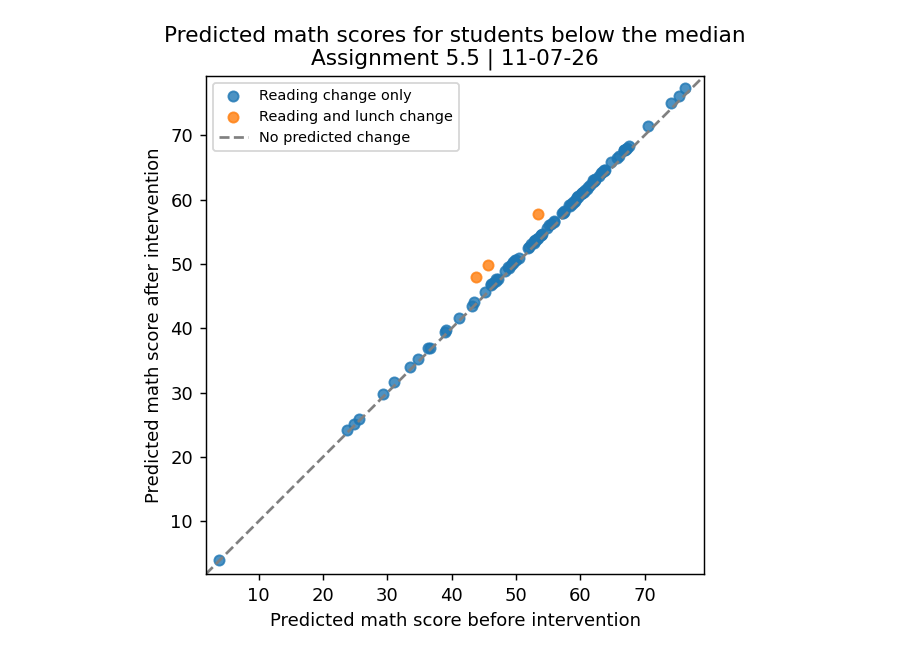

In [13]:
### Step 9 — Compare predicted scores for the same students | Assignment 5.5 | 11-07-26
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))
for changed, group in results.groupby("Lunch changed"):
    label = "Reading and lunch change" if changed else "Reading change only"
    ax.scatter(group["Before"], group["After"], s=32, alpha=0.8, label=label)

low = results[["Before", "After"]].min().min() - 2
high = results[["Before", "After"]].max().max() + 2
ax.plot([low, high], [low, high], "--", color="gray", label="No predicted change")
ax.set(xlim=(low, high), ylim=(low, high), aspect="equal",
       xlabel="Predicted math score before intervention",
       ylabel="Predicted math score after intervention",
       title="Predicted math scores for students below the median\nAssignment 5.5 | 11-07-26")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()